# BGR-kanaler

Et fargebilde i OpenCV har tre kanaler i rekkefølgen **B, G, R**. Hver kanal er en 2D-tabell med tall fra 0 til 255, altså et gråtonebilde: lyst der det er mye av fargen, mørkt der det er lite.

Notatboken viser hver kanal på to måter:

- **øverst** som gråtone, slik kanalen faktisk er lagret
- **nederst** i farge, der de to andre kanalene er satt til 0

Kjør cellene med **Shift+Enter**, eller trykk **Kjør alle**.

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact
import fargelab

print("Bilder i bilder/:", fargelab.bilder)

Bilder i bilder/: ['11_Pro.jpg', '12_Pro.jpg', '23_Pro.jpg', '39_Pro.jpg', '47_Pro.jpg', '57_Pro.jpg', 'Checkerboard_pattern.png', 'eksempel.png', 'grayscale.png', 'hueValueChroma.png', 'stack_2.png', 'testbilde.png']


## Velg et bilde

`fargelab.bilde` er bildet du har åpnet i Fargelab-fanen. Har du ikke åpnet noe der, brukes `eksempel.png`. Du kan også skrive filnavnet til et bilde i `bilder/` selv.

Nye bilder legger du i mappen `bilder/` med Utforsker, eller med **Filer → Legg til filer** øverst til høyre.

In [3]:
filnavn = fargelab.bilde or "eksempel.png"   # eller for eksempel "mittbilde.jpg"

img = cv2.imread(filnavn)
if img is None:
    raise FileNotFoundError(f"Fant ikke {filnavn}. Ligger det i bilder/?")
print(filnavn, img.shape, img.dtype)

eksempel.png (320, 480, 3) uint8


## Del bildet opp i kanaler

`img[:, :, 0]` er B, `1` er G og `2` er R. Hver av dem er 2D (høyde × bredde), og vises derfor som gråtone.

For å se en kanal i farge lager vi et nytt 3-kanals bilde der de to andre kanalene er 0. Gråtonene beholdes i `blue_channel`, `green_channel` og `red_channel`, og fargeversjonene ligger i `blue_img`, `green_img` og `red_img`, så vi kan vise begge.

In [4]:
blue_channel  = img[:, :, 0]
green_channel = img[:, :, 1]
red_channel   = img[:, :, 2]
# Det samme som: blue_channel, green_channel, red_channel = cv2.split(img)

# Én kanal er 2D (gråtone). Sett den inn i et 3-kanals bilde der de to
# andre kanalene er 0, for å se den i farge.
zeros = np.zeros_like(blue_channel)
blue_img  = cv2.merge([blue_channel, zeros, zeros])   # BGR-rekkefølge
green_img = cv2.merge([zeros, green_channel, zeros])
red_img   = cv2.merge([zeros, zeros, red_channel])

print("én kanal:", blue_channel.shape, "  i farge:", blue_img.shape)

én kanal: (320, 480)   i farge: (320, 480, 3)


## Gråtone over farge

Et rutenett med 2 rader og 3 kolonner. To ting er lett å glemme når du viser OpenCV-bilder med matplotlib:

- **`vmin=0, vmax=255`** på gråtonene. Uten dem strekker matplotlib kontrasten, slik at den mørkeste pikselen blir svart og den lyseste hvit, og da kan du ikke sammenligne kanalene med hverandre.
- matplotlib vil ha **RGB**, så fargebildene gjøres om med `cv2.COLOR_BGR2RGB`. Ellers blir blått vist som rødt og rødt som blått.

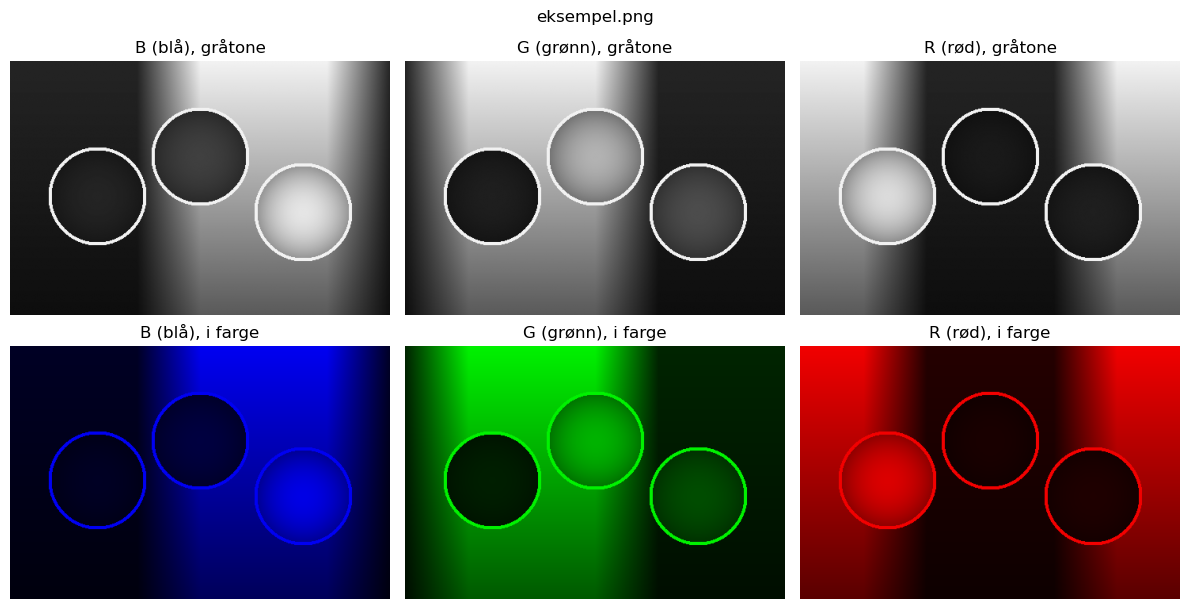

In [5]:
def vis_kanaler(gratone, farget, tittel=""):
    h, w = gratone[0].shape
    fig, ax = plt.subplots(2, 3, figsize=(12, 8 * h / w + 1))
    for i, navn in enumerate(["B (blå)", "G (grønn)", "R (rød)"]):
        ax[0, i].imshow(gratone[i], cmap="gray", vmin=0, vmax=255)
        ax[0, i].set_title(f"{navn}, gråtone")
        ax[1, i].imshow(cv2.cvtColor(farget[i], cv2.COLOR_BGR2RGB))
        ax[1, i].set_title(f"{navn}, i farge")
    for a in ax.flat:
        a.axis("off")
    fig.suptitle(tittel)
    plt.tight_layout()
    plt.show()


vis_kanaler([blue_channel, green_channel, red_channel],
            [blue_img, green_img, red_img],
            filnavn)

## Bytt bilde med en nedtrekksliste

`@interact` lager en nedtrekksliste med bildene i `bilder/`. Velg et bilde, så deles det opp og vises på nytt. Her brukes `cv2.split`, som gjør det samme som `img[:, :, 0]` osv.

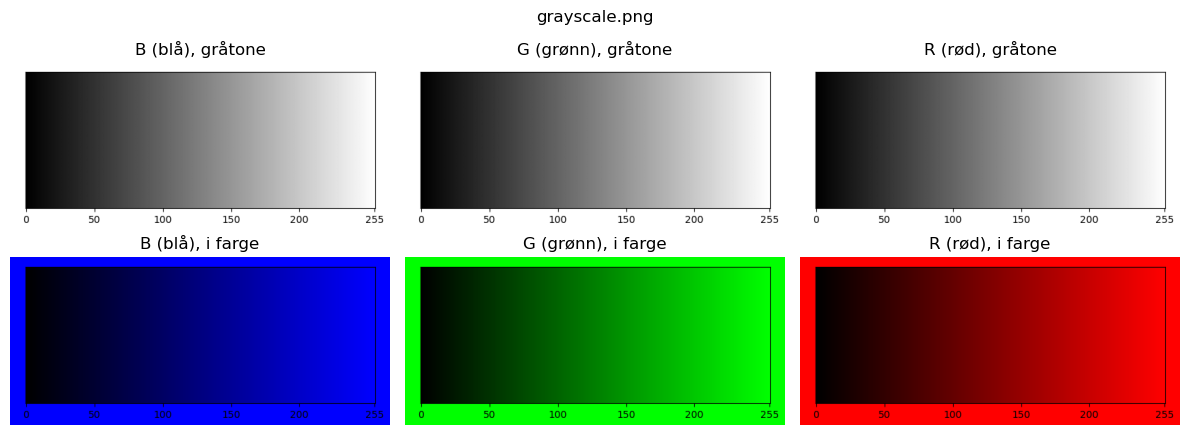

In [5]:
@interact(navn=fargelab.bilder)
def velg_bilde(navn=filnavn):
    bilde = cv2.imread(navn)
    if bilde is None:
        print(navn, "er ikke et bilde OpenCV kan lese.")
        return
    b, g, r = cv2.split(bilde)
    zeros = np.zeros_like(b)
    vis_kanaler([b, g, r],
                [cv2.merge([b, zeros, zeros]), cv2.merge([zeros, g, zeros]), cv2.merge([zeros, zeros, r])],
                navn)

## Mal på et sjakkbrett

Et lite Paint-program med OpenCV. Alle rutene er svarte når du starter. **Klikk på en rute**, så åpnes et vindu med glidebrytere for **B**, **G** og **R**, satt til fargen ruten har nå:

- Ruten får den nye fargen mens du drar. Fargeprøven øverst i vinduet viser BGR-verdiene.
- **OK** beholder fargen. **Avbryt**, ×, Esc eller et klikk utenfor vinduet setter tilbake fargen ruten hadde.
- Under brettet ser du kanalene B, G og R som gråtone, og under dem i farge, der de to andre kanalene er 0 (som `blue_img`, `green_img` og `red_img` over). Begge radene oppdateres mens du maler.
- De grå strekene mellom rutene tegnes bare i bildet du ser, ikke i `brett`, så de kommer ikke med i kanalene.

Klikkene kommer fra `cv2.setMouseCallback`, som i et vanlig OpenCV-vindu. Vinduet er `widgets.Popup`, som bare finnes i Fargelab. Kjør cellen på nytt for å starte med et nytt brett.

In [ ]:
import ipywidgets as widgets

N, RUTE = 6, 30   # N × N ruter på RUTE × RUTE piksler


def lag_brett(n=N, rute=RUTE):
    """n × n ruter på rute × rute piksler, alle svarte."""
    return np.zeros((n * rute, n * rute, 3), np.uint8)   # 3 kanaler, så rutene kan få farger


brett = lag_brett()


def piksler_i_rute(rad, kol):
    """Pikslene i én rute. Det du endrer her, endres i brettet."""
    return brett[rad * RUTE:(rad + 1) * RUTE, kol * RUTE:(kol + 1) * RUTE]


def vis_brett():
    # Grå streker mellom rutene, så du ser dem. De tegnes bare i bildet du ser,
    # ikke i brett, så de kommer ikke med i kanalene under.
    visning = brett.copy()
    visning[::RUTE, :] = visning[:, ::RUTE] = 90
    visning[-1, :] = visning[:, -1] = 90
    cv2.imshow("Paint", visning)
    b, g, r = cv2.split(brett)
    zeros = np.zeros_like(b)
    skille = np.full((brett.shape[0], 8), 128, np.uint8)   # grå strek mellom kanalene

    # Gråtone: hver kanal slik den er lagret (2D)
    cv2.imshow("B | G | R som gråtone", np.hstack([b, skille, g, skille, r]))

    # I farge: hver kanal i et 3-kanals bilde der de to andre kanalene er 0
    skille3 = cv2.merge([skille, skille, skille])
    cv2.imshow("B | G | R i farge", np.hstack([cv2.merge([b, zeros, zeros]), skille3,
                                               cv2.merge([zeros, g, zeros]), skille3,
                                               cv2.merge([zeros, zeros, r])]))


# Pop-up-vinduet: fargeprøve, glidebrytere for B, G og R, og knappene OK og Avbryt
b_slider = widgets.IntSlider(description="B", max=255)
g_slider = widgets.IntSlider(description="G", max=255)
r_slider = widgets.IntSlider(description="R", max=255)
fargeprove = widgets.Output()
ok_knapp = widgets.Button(description="OK", button_style="primary")
avbryt_knapp = widgets.Button(description="Avbryt")
vindu = widgets.Popup([fargeprove, b_slider, g_slider, r_slider,
                       widgets.HBox([ok_knapp, avbryt_knapp])])

valgt = None         # (rad, kol) for ruten i vinduet, eller None
for_endring = None   # fargen ruten hadde da du klikket, så Avbryt kan sette den tilbake


def vis_fargeprove(farge):
    b, g, r = farge
    stripe = np.zeros((40, 300, 3), np.uint8)
    stripe[:] = farge
    lys = 0.114 * b + 0.587 * g + 0.299 * r              # samme vekter som COLOR_BGR2GRAY
    tekst = (0, 0, 0) if lys > 128 else (255, 255, 255)  # svart tekst på lyse farger
    cv2.putText(stripe, f"BGR ({b}, {g}, {r})", (10, 27), cv2.FONT_HERSHEY_SIMPLEX, 0.7, tekst, 2, cv2.LINE_AA)
    with fargeprove:
        cv2.imshow("Farge", stripe)


def mal_rute(_=None):
    """En glidebryter er flyttet: mal ruten med den nye fargen."""
    if valgt is None:
        return
    farge = (b_slider.value, g_slider.value, r_slider.value)
    piksler_i_rute(*valgt)[:] = farge
    vis_fargeprove(farge)
    vis_brett()


for s in (b_slider, g_slider, r_slider):
    s.observe(mal_rute, names="value")


def mus(event, x, y, flags, param):
    global valgt, for_endring
    if event == cv2.EVENT_LBUTTONDOWN:
        rad, kol = y // RUTE, x // RUTE                       # hvilken rute du klikket på
        for_endring = tuple(int(v) for v in brett[y, x])     # numpy: rad (y) først, så kolonne (x)
        valgt = None   # ikke mal mens glidebryterne settes til fargen i ruten
        b_slider.value, g_slider.value, r_slider.value = for_endring
        valgt = (rad, kol)
        vis_fargeprove(for_endring)
        vindu.title = f"Rute rad {rad}, kolonne {kol}"
        vindu.show()


def behold(_=None):
    """OK: behold fargen og lukk vinduet."""
    global valgt
    valgt = None
    vindu.close()


def avbryt(_=None):
    """Avbryt: sett tilbake fargen ruten hadde, og lukk vinduet."""
    global valgt
    if valgt is not None:
        piksler_i_rute(*valgt)[:] = for_endring
        valgt = None
        vis_brett()
    vindu.close()


def lukket(change):
    if not change["new"]:   # lukket med ×, Esc eller et klikk utenfor: som Avbryt
        avbryt()


ok_knapp.on_click(behold)
avbryt_knapp.on_click(avbryt)
vindu.observe(lukket, names="open")

cv2.namedWindow("Paint")
cv2.setMouseCallback("Paint", mus)
vis_brett()

### Prøv selv

- `x // RUTE` og `y // RUTE` gir ruten du klikket på. Klikker du på piksel x = 130, er det kolonne 130 // 60 = 2.
- Mal en rute med BGR (0, 255, 255), som er gul. Den blir hvit i G og R, men svart i B. I fargeraden blir den helt grønn i G og helt rød i R.
- Velg en grå farge, der B, G og R er like, for eksempel (128, 128, 128). Da blir ruten like lys i alle tre kanalene.
- Endre `N` og `RUTE` øverst i cellen for flere eller større ruter.
- Vil du heller starte med et svart-hvitt sjakkbrett, kan du gjøre annenhver rute hvit rett etter `brett = lag_brett()`:

```python
for rad in range(N):
    for kol in range(N):
        if (rad + kol) % 2 == 0:
            brett[rad * RUTE:(rad + 1) * RUTE, kol * RUTE:(kol + 1) * RUTE] = 255
```

- Vil du heller fylle som bøtta i Paint, kan du bruke `cv2.floodFill(brett, None, (x, y), farge)` i `mus`. Den fyller pikselen du klikker på og alle naboer med samme farge.

I vanlig OpenCV på PC-en trenger du også en løkke til slutt, så vinduet holdes åpent: `while cv2.waitKey(20) != 27: pass` (27 er Esc). I Fargelab trengs den ikke, og den ville hengt.